In [6]:
# Import the packages we need
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.stats import mannwhitneyu
from sklearn.model_selection import train_test_split

In [7]:
# Load the dataset, saved in current folder as data.csv
file_path = "data.csv"
df = pd.read_csv(file_path)

# Check the loaded data
print("Dataset shape:", df.shape)
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
display(df.head())

# Separate the 86 permission features from the target label
X = df.drop(columns="Result")
y = df["Result"]

print("Number of features:", X.shape[1])
print("Number of observations:", X.shape[0])
print("\nClass counts:")
print(y.value_counts()) # number of 0s and number of 1s

# Create a group label for each unique permission pattern
# permission group holds each data point with their permissions joined together with "_"
# ex: 0_1_0_1_1
permission_groups = X.astype(str).agg("_".join, axis=1)

print(
    "\nNumber of unique permission patterns:",
    permission_groups.nunique()
)

# Gives count of how many duplicate permission patterns there are (
print(
    "Number of repeated permission-pattern rows:",
    len(permission_groups) - permission_groups.nunique()
)

# Check whether any permission pattern has both labels
# groupby organizes number of 0s and 1s for each unique permission set
# nunique will return 2 if it has both kinds of labels
# Isolates those apps into its own group and prints the total count of them
label_counts = y.groupby(permission_groups).nunique()
conflicting_groups = label_counts[label_counts > 1]
# display(conflicting_groups.head())

print(
    "\nNumber of permission patterns with BOTH labels:",
    len(conflicting_groups)
)

# Create one row per permission pattern for group-based splitting.
# group_labels contains all the unique permission patterns
# Mark patterns that have both labels as -1 (denotes conflicting labels), 1 otherwise
group_labels = y.groupby(permission_groups, sort=False).agg(
    lambda labels: labels.iloc[0] if labels.nunique() == 1 else -1
)

# deduplicate permission patterns
group_data = X.groupby(permission_groups, sort=False).first()
group_data["Result"] = group_labels 

print("\nGroup-level label counts:")
print(group_data["Result"].value_counts())
print("Group-level dataset shape:", group_data.shape)


Dataset shape: (29332, 87)
Number of rows: 29332
Number of columns: 87


,android.permission.GET_ACCOUNTS,com.sonyericsson.home.permission.BROADCAST_BADGE,android.permission.READ_PROFILE,android.permission.MANAGE_ACCOUNTS,android.permission.WRITE_SYNC_SETTINGS,android.permission.READ_EXTERNAL_STORAGE,android.permission.RECEIVE_SMS,com.android.launcher.permission.READ_SETTINGS,android.permission.WRITE_SETTINGS,com.google.android.providers.gsf.permission.READ_GSERVICES,...,com.android.launcher.permission.UNINSTALL_SHORTCUT,com.sec.android.iap.permission.BILLING,com.htc.launcher.permission.UPDATE_SHORTCUT,com.sec.android.provider.badge.permission.WRITE,android.permission.ACCESS_NETWORK_STATE,com.google.android.finsky.permission.BIND_GET_INSTALL_REFERRER_SERVICE,com.huawei.android.launcher.permission.READ_SETTINGS,android.permission.READ_SMS,android.permission.PROCESS_INCOMING_CALLS,Result
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0


Number of features: 86
Number of observations: 29332

Class counts:
Result
1    14700
0    14632
Name: count, dtype: int64

Number of unique permission patterns: 7395
Number of repeated permission-pattern rows: 21937

Number of permission patterns with BOTH labels: 96

Group-level label counts:
Result
 0    4771
 1    2528
-1      96
Name: count, dtype: int64
Group-level dataset shape: (7395, 87)


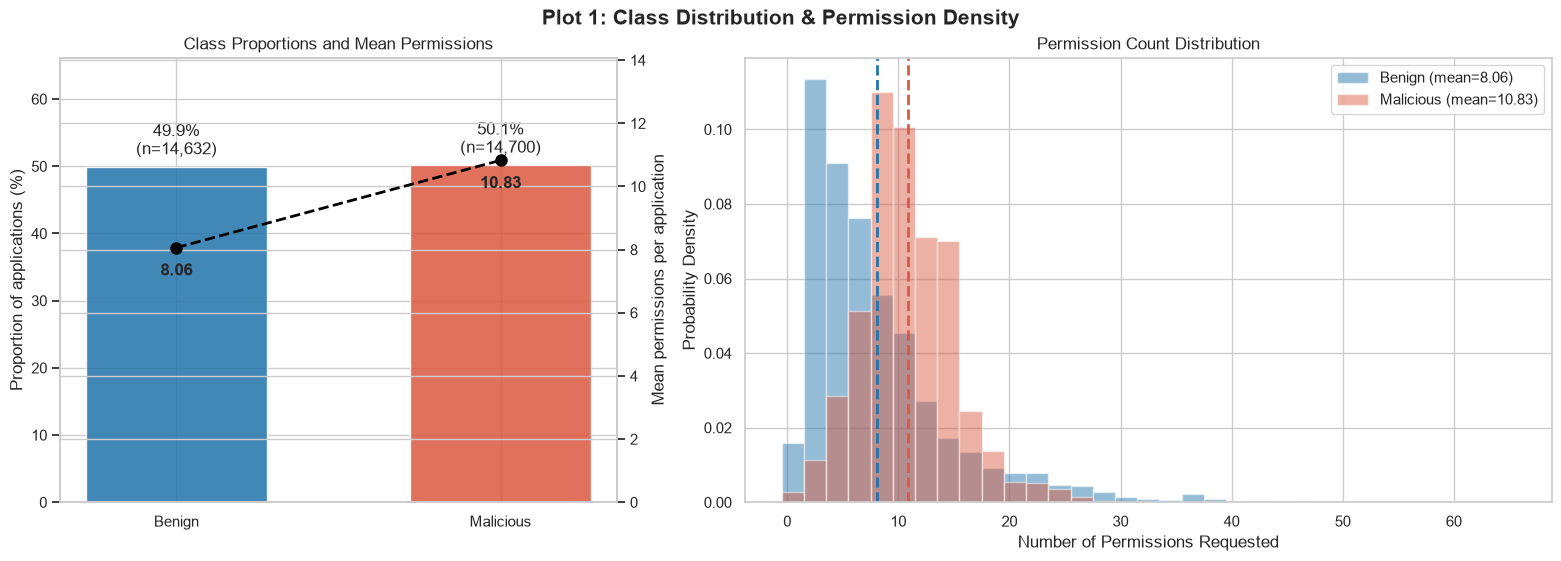

Benign: mean=8.06, median=6
Malicious: mean=10.83, median=10
Difference in means: 2.77
Mann-Whitney p-value: 0
Probability of superiority (ties count as half): 0.712


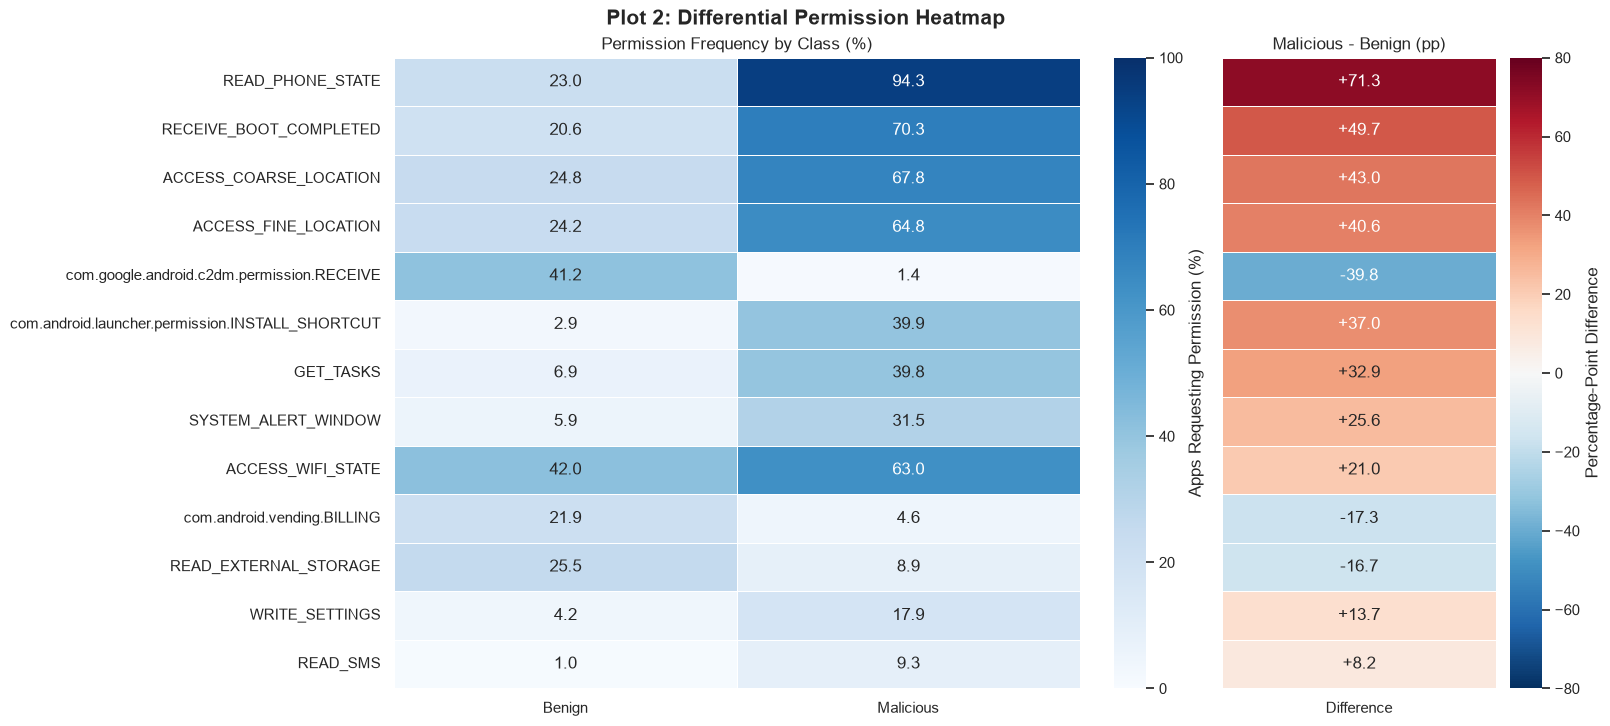


Top differential permissions:
Result                                            Benign  Malicious  \
READ_PHONE_STATE                                   23.00      94.31   
RECEIVE_BOOT_COMPLETED                             20.59      70.27   
ACCESS_COARSE_LOCATION                             24.84      67.84   
ACCESS_FINE_LOCATION                               24.21      64.80   
com.google.android.c2dm.permission.RECEIVE         41.17       1.41   
com.android.launcher.permission.INSTALL_SHORTCUT    2.86      39.88   
GET_TASKS                                           6.86      39.77   
SYSTEM_ALERT_WINDOW                                 5.86      31.48   
ACCESS_WIFI_STATE                                  42.00      62.97   
com.android.vending.BILLING                        21.92       4.64   
READ_EXTERNAL_STORAGE                              25.52       8.86   
WRITE_SETTINGS                                      4.19      17.94   
READ_SMS                                      

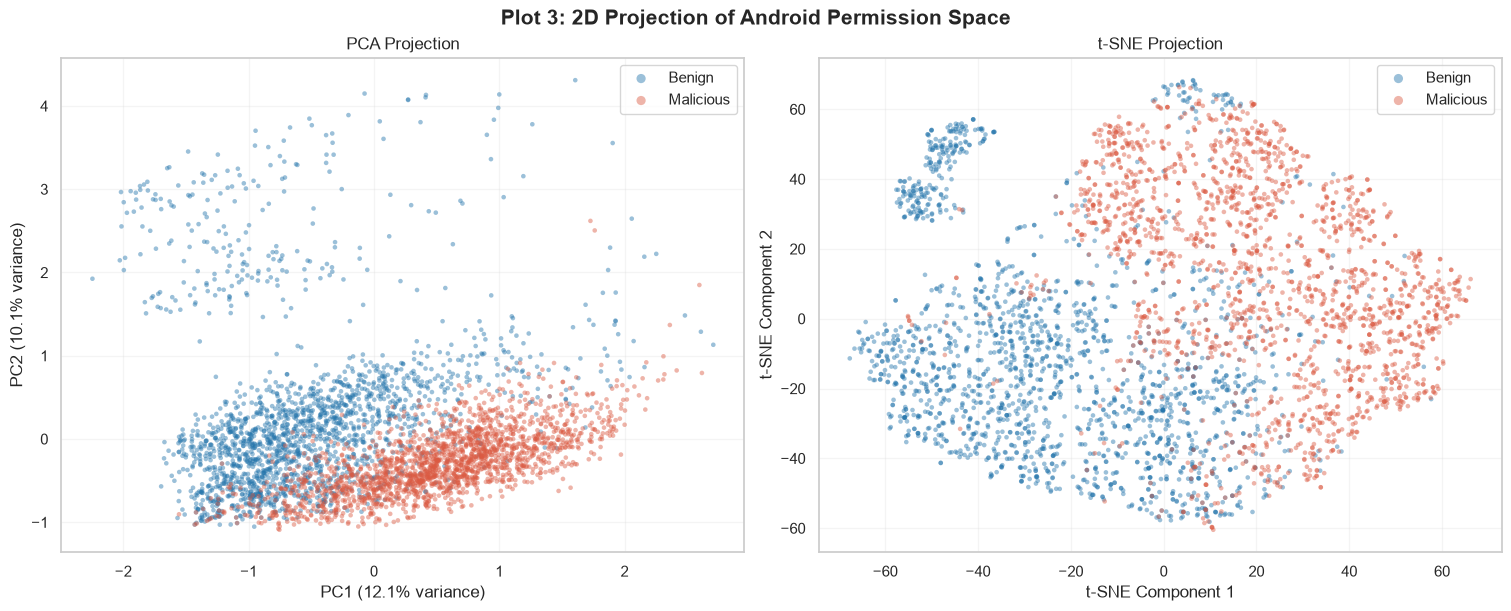

In [10]:
# ============================================================
# Additional Data Analysis: Plots
# ============================================================

df = pd.read_csv(file_path) #reset df, to reset changes when rerunning this cell
sns.set_theme(style='whitegrid')

# Consistent class colors throughout all plots
COLORS = {0: '#2374AB', 1: '#DB5A42'}
NAMES = {0: 'Benign', 1: 'Malicious'}
ORDER = [0, 1]
SEED = 42

# Separate features from target
# print(df.shape)
# print(df.columns)
permission_cols = df.columns.drop('Result').tolist()

# Verify the dataset
# print(len(permission_cols))
assert len(permission_cols) == 86
assert y.isin([0, 1]).all()
assert X.isin([0, 1]).all().all()

# Each permission column is 1 when requested, 0 otherwise
df['total_permissions'] = X.sum(axis=1)


# ============================================================
# PLOT 1: Class Distribution & Permission Density
# ============================================================

counts = y.value_counts().reindex(ORDER)
shares = counts / len(df) * 100

means = df.groupby('Result')['total_permissions'].mean().reindex(ORDER)
medians = df.groupby('Result')['total_permissions'].median().reindex(ORDER)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15.5, 5.5),
    gridspec_kw={'width_ratios': [1, 1.45]},
    constrained_layout=True
)

# Left panel: class proportions (left axis)
positions = np.arange(2)
bars = ax1.bar(
    positions, shares.values,
    color=[COLORS[c] for c in ORDER],
    width=0.56, alpha=0.86
)

ax1.set_xticks(positions, [NAMES[c] for c in ORDER])
ax1.set_ylabel('Proportion of applications (%)')
ax1.set_ylim(0, max(shares) * 1.32)
ax1.set_title('Class Proportions and Mean Permissions')

for bar, cls in zip(bars, ORDER):
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1.2,
        f'{shares[cls]:.1f}%\n(n={counts[cls]:,})',
        ha='center', va='bottom'
    )

# Secondary axis: average number of permissions
ax1_right = ax1.twinx()

ax1_right.plot(
    positions, means.values,
    'o--', color='black', linewidth=2, markersize=8
)

ax1_right.set_ylabel('Mean permissions per application')
ax1_right.set_ylim(0, max(means) * 1.30)

for i, mean in enumerate(means.values):
    ax1_right.annotate(
        f'{mean:.2f}', (positions[i], mean),
        xytext=(0, -20), textcoords='offset points',
        ha='center', fontweight='bold'
    )

# Right panel: permission-count histograms
bins = np.arange(-0.5, df['total_permissions'].max() + 2.5, 2)

for cls in ORDER:
    values = df.loc[
        df['Result'] == cls, 'total_permissions'
    ]

    ax2.hist(
        values, bins=bins, density=True, alpha=0.48,
        color=COLORS[cls], edgecolor='white',
        label=f'{NAMES[cls]} (mean={means[cls]:.2f})'
    )

    ax2.axvline(
        means[cls], color=COLORS[cls],
        linestyle='--', linewidth=2
    )

ax2.set_title('Permission Count Distribution')
ax2.set_xlabel('Number of Permissions Requested')
ax2.set_ylabel('Probability Density')
ax2.legend()

fig.suptitle(
    'Plot 1: Class Distribution & Permission Density',
    fontsize=15, fontweight='bold'
)

plt.show()

# Numerical comparison and one-sided statistical test
benign_counts = df.loc[y == 0, 'total_permissions']
malware_counts = df.loc[y == 1, 'total_permissions']

u_stat, p_value = mannwhitneyu(
    malware_counts, benign_counts, alternative='greater'
)

print(f"Benign: mean={means[0]:.2f}, median={medians[0]:.0f}")
print(f"Malicious: mean={means[1]:.2f}, median={medians[1]:.0f}")
print(f"Difference in means: {means[1] - means[0]:.2f}")
print(f"Mann-Whitney p-value: {p_value:.3g}")
print(
    "Probability of superiority (ties count as half):",
    round(u_stat / (len(malware_counts) * len(benign_counts)), 3)
)


# ============================================================
# PLOT 2: Differential Permission Heatmap
# ============================================================

# Calculate the percentage requesting each permission by class
frequency = (
    df.groupby('Result')[permission_cols].mean() * 100
).T

frequency = frequency.rename(columns=NAMES)

# Positive = more prevalent in malware
# Negative = more prevalent in benign apps
frequency['Difference'] = (
    frequency['Malicious'] - frequency['Benign']
)

# Top 12 permissions by absolute percentage-point difference
top_permissions = (
    frequency['Difference'].abs()
    .nlargest(12).index.tolist()
)

# Explicitly include the permissions of interest
focus_permissions = [
    'android.permission.READ_SMS',
    'android.permission.SYSTEM_ALERT_WINDOW',
    'android.permission.RECEIVE_BOOT_COMPLETED'
]

selected = list(dict.fromkeys(
    top_permissions +
    [p for p in focus_permissions if p in permission_cols]
))

selected.sort(
    key=lambda p: abs(frequency.loc[p, 'Difference']),
    reverse=True
)

plot_data = frequency.loc[selected].copy()

# Shorten Android permission names for readability
plot_data.index = [
    p.replace('android.permission.', '', 1)
    if p.startswith('android.permission.') else p
    for p in selected
]

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(16, max(6.2, len(selected)*0.55)),
    gridspec_kw={'width_ratios': [2.5, 1]},
    constrained_layout=True
)

# Class-specific frequencies
sns.heatmap(
    plot_data[['Benign', 'Malicious']],
    annot=True, fmt='.1f',
    cmap='Blues', vmin=0, vmax=100,
    linewidths=0.6, linecolor='white',
    cbar_kws={'label': 'Apps Requesting Permission (%)'},
    ax=ax1
)

ax1.set_title('Permission Frequency by Class (%)')
ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.tick_params(axis='y', labelrotation=0)

# Differential frequency heatmap
max_diff = np.ceil(
    plot_data['Difference'].abs().max()/10
) * 10

sns.heatmap(
    plot_data[['Difference']],
    annot=True, fmt='+.1f',
    cmap='RdBu_r', center=0,
    vmin=-max_diff, vmax=max_diff,
    linewidths=0.6, linecolor='white',
    cbar_kws={'label': 'Percentage-Point Difference'},
    ax=ax2
)

ax2.set_title('Malicious - Benign (pp)')
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.tick_params(axis='y', left=False, labelleft=False)
ax2.set_xticklabels(['Difference'], rotation=0)

fig.suptitle(
    'Plot 2: Differential Permission Heatmap',
    fontsize=15, fontweight='bold'
)

plt.show()

print("\nTop differential permissions:")
print(plot_data.round(2))


# ============================================================
# PLOT 3: PCA and t-SNE Projection of 86D Space
# ============================================================

# Avoid excessively repeating identical permission patterns
# in the projections. The original data remains unchanged.
unique_profiles = df.drop_duplicates(
    subset=permission_cols + ['Result']
)

# Balanced sampling to keep t-SNE computationally manageable
MAX_PER_CLASS = 2000

samples = [
    unique_profiles.loc[
        unique_profiles['Result'] == cls
    ].sample(
        n=min(
            MAX_PER_CLASS,
            (unique_profiles['Result'] == cls).sum()
        ),
        random_state=SEED
    )
    for cls in ORDER
]

projection_df = pd.concat(
    samples, ignore_index=True
).sample(frac=1, random_state=SEED)

X_proj = projection_df[permission_cols].to_numpy(dtype=np.float32)
y_proj = projection_df['Result'].to_numpy()

# PCA: 86 dimensions -> 2 dimensions
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_proj)

print(
    "PCA explained variance:",
    pca.explained_variance_ratio_
)
print(
    "Total variance explained:",
    pca.explained_variance_ratio_.sum()
)

# PCA preprocessing before t-SNE
# Reduces computational cost and noisy dimensions
pca_pre = PCA(n_components=30, random_state=SEED)
X_reduced = pca_pre.fit_transform(X_proj)

# t-SNE: 30 dimensions -> 2 dimensions
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=SEED
)

X_tsne = tsne.fit_transform(X_reduced)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6),
    constrained_layout=True
)

for ax, coords, title in [
    (axes[0], X_pca, 'PCA Projection'),
    (axes[1], X_tsne, 't-SNE Projection')
]:
    for cls in ORDER:
        mask = y_proj == cls

        ax.scatter(
            coords[mask, 0],
            coords[mask, 1],
            s=11, alpha=0.45,
            color=COLORS[cls],
            label=NAMES[cls],
            edgecolors='none',
            rasterized=True
        )

    ax.set_title(title)
    ax.legend(markerscale=2)
    ax.grid(alpha=0.2)

axes[0].set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)"
)
axes[0].set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)"
)

axes[1].set_xlabel('t-SNE Component 1')
axes[1].set_ylabel('t-SNE Component 2')

fig.suptitle(
    'Plot 3: 2D Projection of Android Permission Space',
    fontsize=15, fontweight='bold'
)

plt.show()


In [11]:
# print(group_labels.index.shape)
# print("First 10 permission patterns:")
# print(group_labels.index[3])
# Split unique permission patterns into training (70%) and testing (30%)
train_groups, test_groups = train_test_split(
    group_labels.index.tolist(),
    test_size=0.30,
    random_state=42
)

# Put each original app in the split according to its permission pattern
# test and train don't share any permission patterns, so that the model can't learn an exact pattern
#  and then be able to apply to test
train_mask = permission_groups.isin(train_groups)
test_mask = permission_groups.isin(test_groups)

train_data = df.loc[train_mask].copy()
test_data = df.loc[test_mask].copy()

print("Training rows:", len(train_data))
print("Test rows:", len(test_data))
print(
    "Permission patterns shared between splits:",
    len(set(train_groups) & set(test_groups))
)

Training rows: 22096
Test rows: 7236
Permission patterns shared between splits: 0
